In [1]:
import os, sys
import warnings
warnings.filterwarnings('ignore')
from IPython.display import display, Markdown, Math
import numpy as np
import pandas as pd
import networkx as nx
from scipy.stats import norm
pd.set_option('display.max_columns', None)
pd.set_option('display.max_rows', None)

# Versión local de la librería: se busca src/pmule.py subiendo desde el directorio actual
_aqui = os.path.abspath('.')
while _aqui != os.path.dirname(_aqui) and not os.path.isfile(os.path.join(_aqui, 'src', 'pmule.py')):
    _aqui = os.path.dirname(_aqui)
sys.path.append(os.path.join(_aqui, 'src'))
from pmule import (PredecessorTable, ProjectGraph, EarnedValue,
                   pinta_tikz, plot_cargas, plot_curvas_valor_ganado,
                   tanto_por_uno, ordena_rutas)

GANTT_PARAMS = dict(arrows=True)   # flechas de prelación en los diagramas de Gantt (rojas las críticas)

In [2]:
%%capture
%mkdir -p ~/temp
%cd ~/temp

# Enunciado

Considere el proyecto cuyo cuadro de prelaciones y duraciones (semanas) se adjunta. Cada actividad consume cada semana la cantidad de combustible indicada (litros/semana). El suministrador entrega como máximo 70 litros por semana.

In [3]:
pregunta_1 = "1. Dibuje el diagrama de consumo semanal con las actividades en su inicio más temprano. ¿En qué semanas se supera el suministro?  "
pregunta_2 = "2. Si no se puede almacenar combustible de una semana para la siguiente, reprograme el proyecto para respetar el suministro (algoritmo de asignación). ¿Cuánto se alarga?  "
pregunta_3 = "3. Si en cambio se dispone de un depósito donde guardar lo no consumido, la restricción pasa a ser acumulada: el consumo acumulado hasta cada semana no puede superar el suministro acumulado. Compruebe si la programación original la cumple.  "
pregunta_4 = "4. Compare ambas situaciones. ¿Qué tipo de recurso son los operarios de los ejercicios anteriores?  "

for item in sorted(dir()):
    if item.startswith('pregunta_'):
        display(Markdown(eval(item)))

1. Dibuje el diagrama de consumo semanal con las actividades en su inicio más temprano. ¿En qué semanas se supera el suministro?  

2. Si no se puede almacenar combustible de una semana para la siguiente, reprograme el proyecto para respetar el suministro (algoritmo de asignación). ¿Cuánto se alarga?  

3. Si en cambio se dispone de un depósito donde guardar lo no consumido, la restricción pasa a ser acumulada: el consumo acumulado hasta cada semana no puede superar el suministro acumulado. Compruebe si la programación original la cumple.  

4. Compare ambas situaciones. ¿Qué tipo de recurso son los operarios de los ejercicios anteriores?  

In [4]:
#| tbl-cap: "Cuadro de datos del enunciado"
#| label: tbl-datosEnunciado
datos_enunciado = pd.DataFrame([
#  activity, predecessor, duration, resources
    ('A'     , '---'      , 3       , 50       ),
    ('B'     , '---'      , 5       , 10       ),
    ('C'     , 'A'        , 5       , 50       ),
    ('D'     , 'B,C'      , 1       , 30       ),
    ('E'     , 'D'        , 2       , 30       ),
    ('F'     , 'D'        , 5       , 20       ),
    ('G'     , 'C'        , 5       , 50       ),
    ('H'     , 'G'        , 1       , 40       ),
    ('I'     , 'E,F,H'    , 1       , 10       ),
], columns=['activity', 'predecessor', 'duration', 'resources']).set_index('activity')
datos_enunciado

,predecessor,duration,resources
activity,,,
A,---,3,50
B,---,5,10
C,A,5,50
D,"B,C",1,30
E,D,2,30
F,D,5,20
G,C,5,50
H,G,1,40
I,"E,F,H",1,10


# Resolución

In [5]:
datos_proyecto = datos_enunciado.copy()
prelaciones = PredecessorTable.from_dataframe_of_strings(datos_proyecto, activity='activity', predecessor='predecessor')
proyecto = prelaciones.create_project()
suministro = 70

## Apartado 1

In [6]:
display(Markdown(pregunta_1))

1. Dibuje el diagrama de consumo semanal con las actividades en su inicio más temprano. ¿En qué semanas se supera el suministro?  

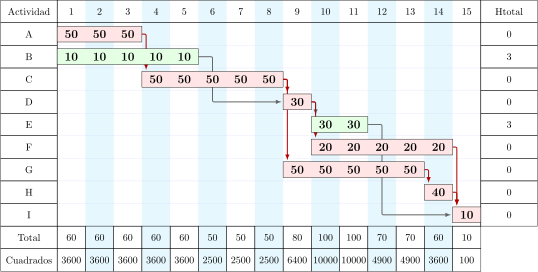

In [7]:
#| fig-cap: "Diagrama de Gantt con el consumo semanal"
#| label: fig-ganttInicial
gantt_inicial, dibujo = proyecto.copy().gantt_cargas(datos_proyecto.copy(), 'duration', 'resources', report=False, tikz=True, params=GANTT_PARAMS)
pinta_tikz(dibujo)

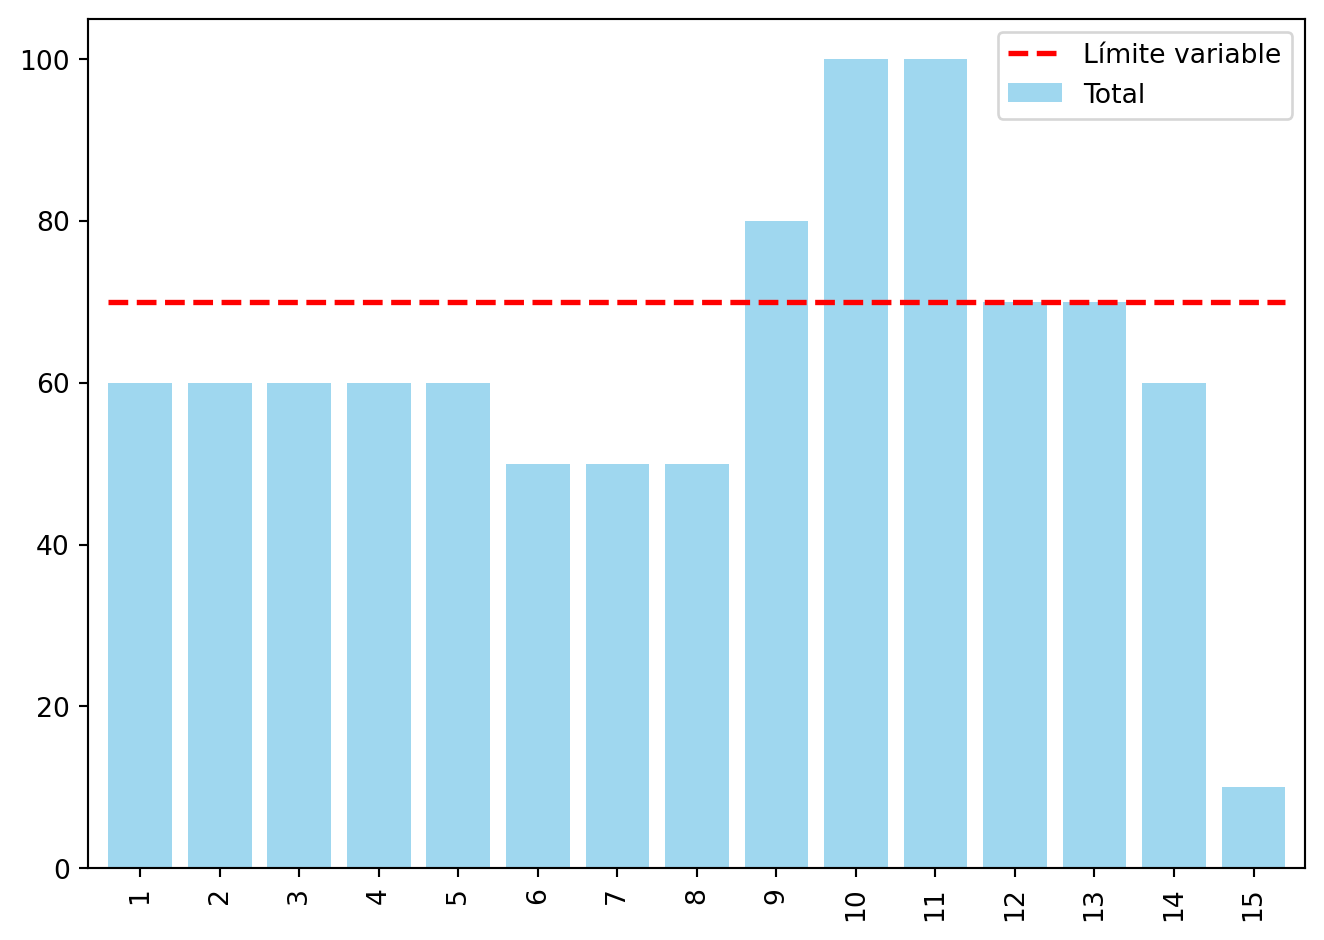

In [8]:
#| fig-cap: "Consumo semanal frente al suministro"
#| label: fig-cargasInicial
plot_cargas(gantt_df=gantt_inicial, limite_maximo_recursos=[suministro])

In [9]:
consumo = gantt_inicial.data.loc['Total'].drop('H_total').astype(float)
exceso = consumo[consumo > suministro]
Markdown(f'Se supera el suministro en las semanas {", ".join(str(t) for t in exceso.index)} (máximo {int(consumo.max())} litros).')

Se supera el suministro en las semanas 9, 10, 11 (máximo 100 litros).

## Apartado 2

In [10]:
display(Markdown(pregunta_2))

2. Si no se puede almacenar combustible de una semana para la siguiente, reprograme el proyecto para respetar el suministro (algoritmo de asignación). ¿Cuánto se alarga?  

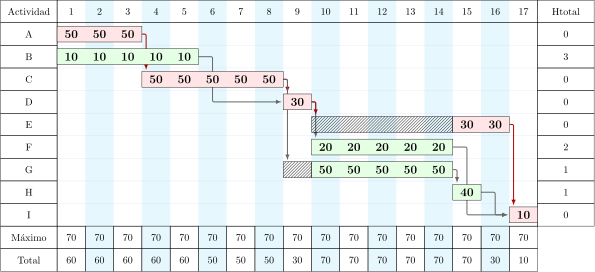

In [11]:
#| fig-cap: "Diagrama de Gantt tras la asignación"
#| label: fig-ganttAsignado
proyecto_asignado = proyecto.copy()
datos_asignados, gantt_asignado, dibujo = proyecto_asignado.asignar(
    data=datos_proyecto.copy(), duration_label='duration', resource_label='resources',
    maximo=[suministro], report=False, params=dict(period_width=1, **GANTT_PARAMS))
pinta_tikz(dibujo)

In [12]:
duracion_inicial = proyecto.duration(datos_proyecto['duration'])
duracion_asignada = len(gantt_asignado.data.columns.drop('H_total'))
Markdown(f'Sin almacenamiento el proyecto pasa de {duracion_inicial} a {duracion_asignada} semanas.')

Sin almacenamiento el proyecto pasa de 15 a 17 semanas.

## Apartado 3

In [13]:
display(Markdown(pregunta_3))

3. Si en cambio se dispone de un depósito donde guardar lo no consumido, la restricción pasa a ser acumulada: el consumo acumulado hasta cada semana no puede superar el suministro acumulado. Compruebe si la programación original la cumple.  

In [14]:
acumulado = pd.DataFrame({'consumo acumulado': consumo.cumsum(), 'suministro acumulado': suministro * np.arange(1, len(consumo) + 1)})
acumulado['cumple'] = acumulado['consumo acumulado'] <= acumulado['suministro acumulado']
acumulado.T

,1,2,3,4,5,6,7,8,9,10,11,12,13,14,15
consumo acumulado,60.0,120.0,180.0,240.0,300.0,350.0,400.0,450.0,530.0,630.0,730.0,800.0,870.0,930.0,940.0
suministro acumulado,70,140,210,280,350,420,490,560,630,700,770,840,910,980,1050
cumple,True,True,True,True,True,True,True,True,True,True,True,True,True,True,True


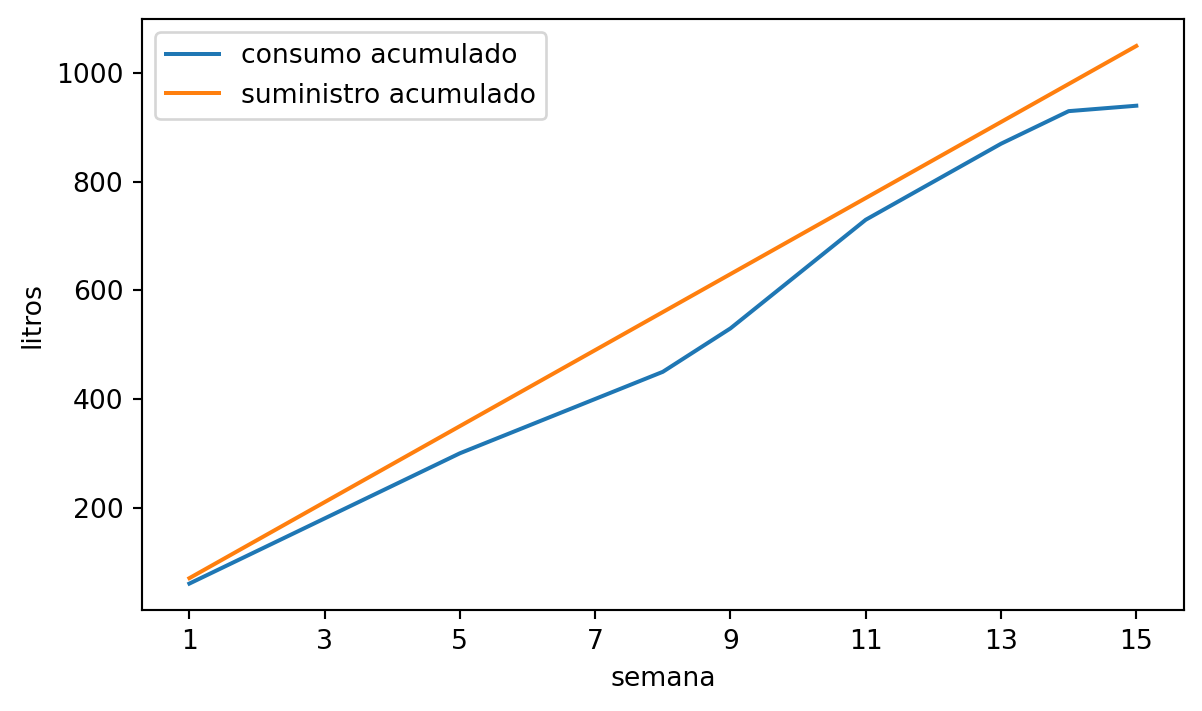

In [15]:
#| fig-cap: "Consumo y suministro acumulados"
#| label: fig-acumulado
ax = acumulado[['consumo acumulado', 'suministro acumulado']].plot(figsize=(7, 4)); ax.set_xlabel('semana'); ax.set_ylabel('litros');

In [16]:
Markdown('Con depósito la programación original ' + ('es viable: el depósito absorbe los picos con lo sobrante de las semanas de menos consumo.' if acumulado['cumple'].all() else f'tampoco es viable: en la semana {acumulado.index[~acumulado["cumple"]][0]} el consumo acumulado supera lo entregado hasta entonces.'))

Con depósito la programación original es viable: el depósito absorbe los picos con lo sobrante de las semanas de menos consumo.

## Apartado 4

In [17]:
display(Markdown(pregunta_4))

4. Compare ambas situaciones. ¿Qué tipo de recurso son los operarios de los ejercicios anteriores?  

Un recurso no almacenable (mano de obra, maquinaria, un suministro que no cabe en depósito) impone una restricción semana a semana; uno almacenable impone una restricción acumulada, mucho menos exigente. Los operarios son del primer tipo: las horas de un operario que no se usan esta semana no se guardan para la siguiente. Por eso los recursos renovables se tratan con asignación y los consumibles con balances acumulados (y, si hace falta, un depósito dimensionado con la diferencia máxima entre las dos curvas).